<a href="https://colab.research.google.com/github/drdave-teaching/OPIM3510-BDA1/blob/main/M1_Python_Bootcamp/Week03_EDA/Project2_BasicEDA_answers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practice: Basic EDA (answers)
**OPIM 3510 Python Bootcamp · Dr. Dave Wanik · University of Connecticut**

-----------------------------------------------------------

Get your plots and tables on!!! We'll use **real Connecticut home sales** (October 2024 - September 2025): sale price, town, type of home, and house features like living area and bedrooms. The data is in the course GitHub repo, so reading it is one line.

Use `pandas`, `matplotlib` and/or `seaborn`. Try it first - THEN check your work. You should be able to do this in about 15 minutes once you really know your stuff.

**(Mock rubric) 100 pts, 10 pts each.**

1. Check the shape, column names and data types. Which columns are text (categories)?
2. Return all of the unique values of `residential_type`. Then make a table of the mean, std, min and max of `sale_price` by `residential_type`. Check the shape of the table.
3. Subset all rows where `residential_type` is `Single Family` and print the shape. Call this variable `x1`.
4. Subset all rows where `residential_type` is `Condo` and print the shape. Call this variable `x2`.
5. Make a histogram of `x1['living_area_sqft']`, colored blue, with a nice title and axis labels.
6. Make a histogram of `x2['living_area_sqft']`, colored red, with a nice title and axis labels.
7. Make a scatterplot using `df` of `living_area_sqft` (x) vs. `sale_price` (y).
8. Make a two-panel scatterplot of `living_area_sqft` vs. `sale_price`: the left panel is `x1` (blue dots) and the right panel is `x2` (red triangles). Give each panel a title and axis labels.
9. Make a density plot of `sale_price` for sales under \$2 million, in a color of your choice, with nice labels and a title.
10. Make a scatterplot of `longitude` (x) vs. `latitude` (y) - it should look like Connecticut! - and color the dots by `sale_price` using `seaborn`. Use the sales under \$2 million so the colors aren't washed out. [Here's the seaborn documentation](https://seaborn.pydata.org/generated/seaborn.scatterplot.html) for hackable examples.


# Import modules and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM3510-BDA1/main/data/ct_home_sales_2025.csv"
df = pd.read_csv(DATA_URL)
df.head()

,town,date_recorded,residential_type,sale_price,assessed_value,living_area_sqft,bedrooms,full_baths,half_baths,total_rooms,year_built,stories,lot_acres,style,condition,heat_fuel,air_conditioning,fireplaces,longitude,latitude
0,Marlborough,0024-10-15,Single Family,256500.0,334650,3332.0,4.0,2.0,1.0,10.0,1740.0,2.00,4.25,Old Style,Good,Oil,NaN,4.0,-72.433,41.608
1,Marlborough,0024-10-24,Single Family,775000.0,427990,2746.0,4.0,3.0,0.0,9.0,1749.0,2.00,0.40,Old Style,Excellent,Propane Gas,Central,3.0,-72.471,41.637
2,Marlborough,0024-10-30,Single Family,370000.0,174620,1467.0,3.0,3.0,0.0,6.0,1965.0,1.00,1.78,Ranch,Average,Oil,Central,1.0,-72.468,41.679
3,Marlborough,0024-10-31,Single Family,186000.0,153210,1545.0,3.0,1.0,0.0,5.0,1938.0,1.75,0.87,Cape,Good,Oil,NaN,0.0,-72.466,41.675
4,Marlborough,0024-10-31,Single Family,375000.0,240170,2273.0,3.0,2.0,1.0,6.0,1985.0,2.00,5.36,Colonial,Good,Oil,NaN,2.0,-72.438,41.612


# Q1
Check the shape, column names and data types. Which columns are text (categories)?

In [2]:
# shape (ROWS, COLUMNS)
print(df.shape)

# data types - object/str columns are text
df.dtypes

# text columns: town, date_recorded, residential_type, style, condition, heat_fuel, air_conditioning

(27313, 20)


town                 object
date_recorded        object
residential_type     object
sale_price          float64
assessed_value        int64
living_area_sqft    float64
bedrooms            float64
full_baths          float64
half_baths          float64
total_rooms         float64
year_built          float64
stories             float64
lot_acres           float64
style                object
condition            object
heat_fuel            object
air_conditioning     object
fireplaces          float64
longitude           float64
latitude            float64
dtype: object

# Q2
Return all of the unique values of `residential_type`. Then make a table of the mean, std, min and max of `sale_price` by `residential_type`. Check the shape of the table.

In [3]:
# unique values in one column
print(df['residential_type'].unique())

# statistics by group
table = df.groupby('residential_type')['sale_price'].agg(['mean', 'std', 'min', 'max'])
print(table.shape) # 5 types of home, 4 statistics
table

['Single Family' 'Condo' 'Two Family' 'Three Family' 'Four Family']
(5, 4)


,mean,std,min,max
residential_type,,,,
Condo,378966.267643,376403.674325,5000.0,6200000.0
Four Family,544523.993333,272566.050823,210000.0,2300000.0
Single Family,665622.760882,837470.726584,6000.0,21000000.0
Three Family,453625.720643,162927.543584,76000.0,1300000.0
Two Family,437479.531098,236416.259138,55000.0,2935000.0


# Q3
Subset all rows where `residential_type` is `Single Family` and print the shape. Call this variable `x1`.

In [4]:
x1 = df[df['residential_type'] == 'Single Family']
x1.shape

(20548, 20)

# Q4
Subset all rows where `residential_type` is `Condo` and print the shape. Call this variable `x2`.

In [5]:
x2 = df[df['residential_type'] == 'Condo']
x2.shape

(4166, 20)

# Q5
Make a histogram of `x1['living_area_sqft']`, colored blue, with a nice title and axis labels.

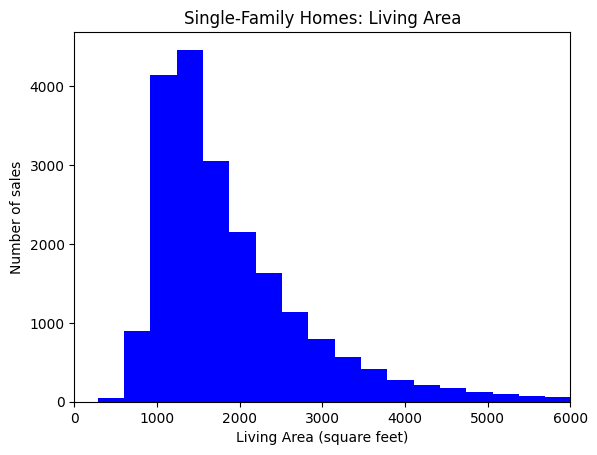

In [6]:
plt.hist(x1['living_area_sqft'], bins=50, color='blue')
plt.xlim(0, 6000) # a few giant homes stretch the axis
plt.xlabel('Living Area (square feet)')
plt.ylabel('Number of sales')
plt.title('Single-Family Homes: Living Area')
plt.show()

# Q6
Make a histogram of `x2['living_area_sqft']`, colored red, with a nice title and axis labels.

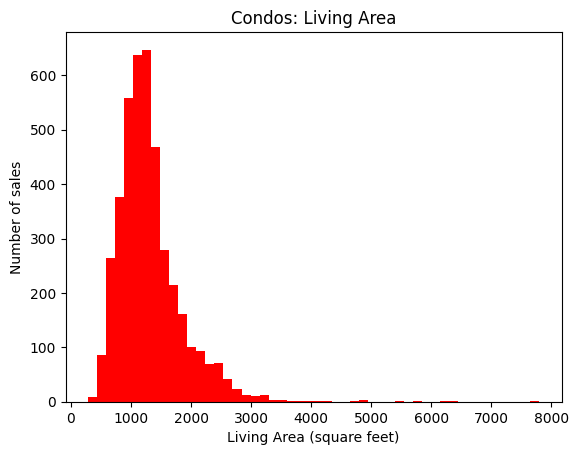

In [7]:
plt.hist(x2['living_area_sqft'], bins=50, color='red')
plt.xlabel('Living Area (square feet)')
plt.ylabel('Number of sales')
plt.title('Condos: Living Area')
plt.show()

# Q7
Make a scatterplot using `df` of `living_area_sqft` (x) vs. `sale_price` (y).

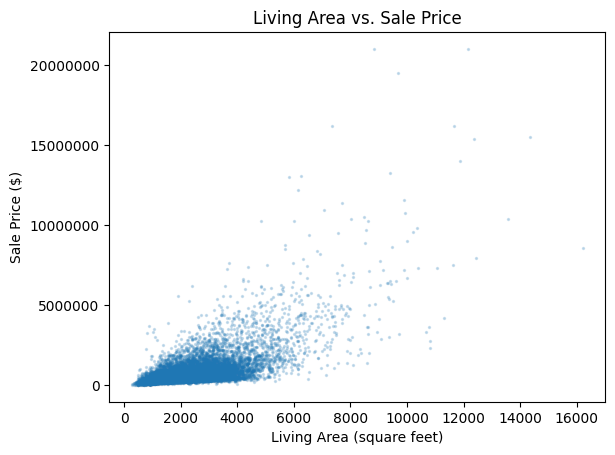

In [8]:
plt.scatter(x=df['living_area_sqft'], y=df['sale_price'], s=2, alpha=0.2)
plt.xlabel('Living Area (square feet)')
plt.ylabel('Sale Price ($)')
plt.ticklabel_format(style='plain', axis='y')
plt.title('Living Area vs. Sale Price')
plt.show()

# Q8
Make a two-panel scatterplot of `living_area_sqft` vs. `sale_price`: the left panel is `x1` (blue dots) and the right panel is `x2` (red triangles). Give each panel a title and axis labels.

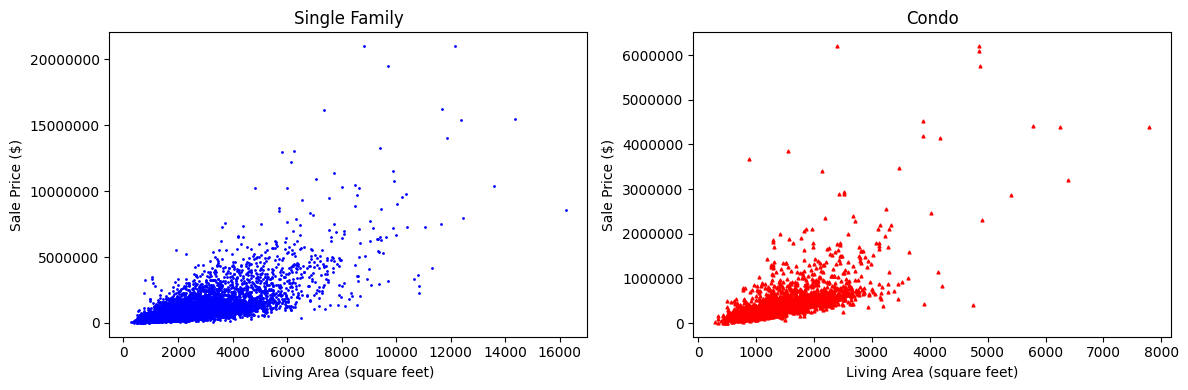

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4)) # 1 row, 2 columns

ax1.scatter(x1['living_area_sqft'], x1['sale_price'], color='blue', marker='.', s=4)
ax1.set_title('Single Family')
ax1.set_xlabel('Living Area (square feet)')
ax1.set_ylabel('Sale Price ($)')
ax1.ticklabel_format(style='plain', axis='y')

ax2.scatter(x2['living_area_sqft'], x2['sale_price'], color='red', marker='^', s=4)
ax2.set_title('Condo')
ax2.set_xlabel('Living Area (square feet)')
ax2.set_ylabel('Sale Price ($)')
ax2.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

# Q9
Make a density plot of `sale_price` for sales under \$2 million, in a color of your choice, with nice labels and a title.

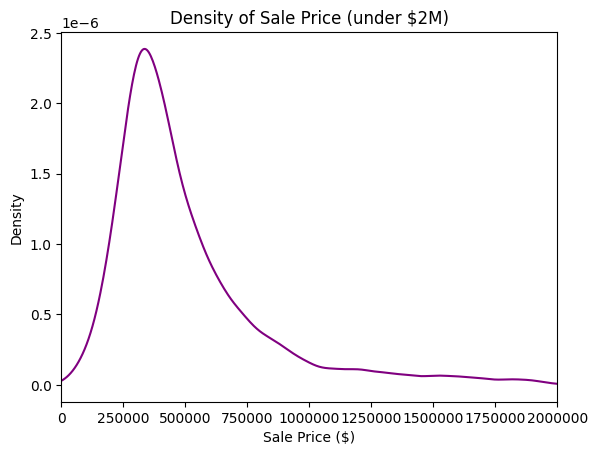

In [10]:
under_2m = df[df['sale_price'] < 2000000]

under_2m['sale_price'].plot.density(color='purple')
plt.xlim(0, 2000000)
plt.xlabel('Sale Price ($)')
plt.ticklabel_format(style='plain', axis='x')
plt.title('Density of Sale Price (under $2M)')
plt.show()

# Q10
Make a scatterplot of `longitude` (x) vs. `latitude` (y) - it should look like Connecticut! - and color the dots by `sale_price` using `seaborn`. Use the sales under \$2 million so the colors aren't washed out. [Here's the seaborn documentation](https://seaborn.pydata.org/generated/seaborn.scatterplot.html) for hackable examples.

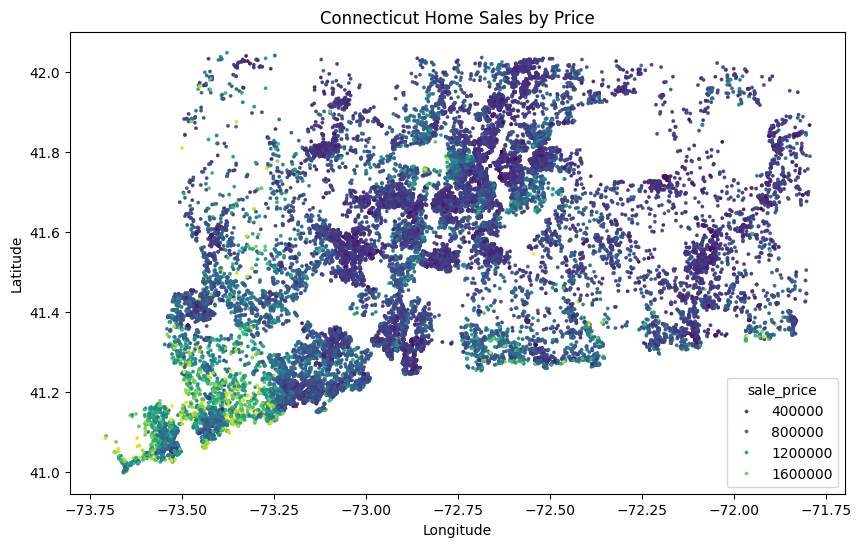

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=under_2m, x='longitude', y='latitude', hue='sale_price', palette='viridis', s=6, edgecolor=None)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Connecticut Home Sales by Price')
plt.show()